## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

## 2. Load Dataset

In [2]:
df =pd.read_csv('../data/raw/predictive_maintenance.csv')

### check dataset

In [3]:
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 3. Data cleaning
- Remove unnecessary columns:

In [4]:
df.drop(["UDI","Product ID"], axis=1, inplace=True)

- encode categorical veriables

In [5]:
le = LabelEncoder()
df["Type"] = le.fit_transform(df["Type"])

## 4. Handle Missing Variables
- median imputation

In [6]:
imputer = SimpleImputer(strategy='median')

numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

## 5. Exploratory Data Analysis

- **Corelation Heatmap**
- This helps identify:
    - Sensor relationships
    - Failure correlations
    - Hidden operational patterns

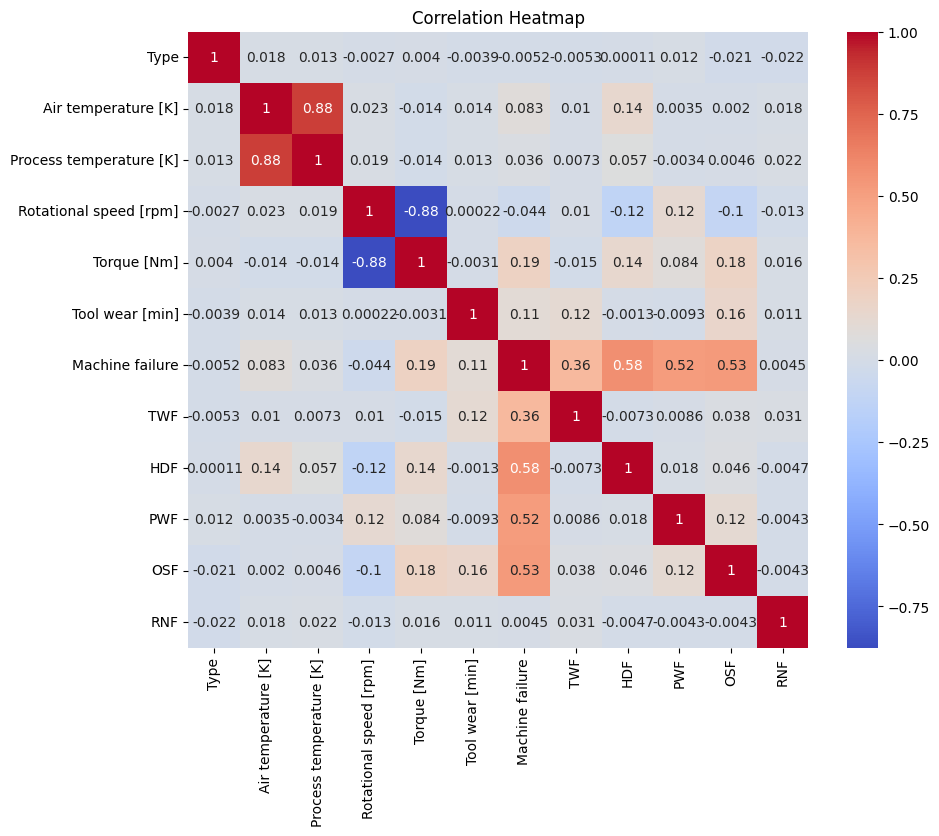

In [7]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

- Failure Distribution

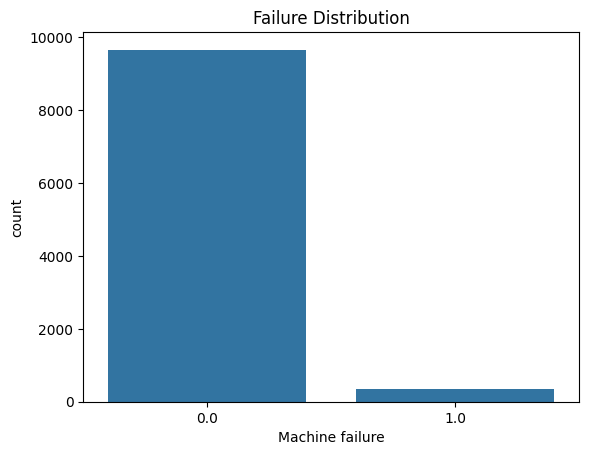

In [8]:
sns.countplot(x='Machine failure', data=df)
plt.title("Failure Distribution")
plt.show()

## 6. Feature Selection

- input features:

In [9]:
X = df.drop("Machine failure", axis=1)

- Target Variables

In [10]:
y = df["Machine failure"]

- Remove leakage columns

## 7. Train Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

## 8. Train Machine Learning Models

- Decision Tree

In [12]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

- Random Forest

In [13]:
rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

- KNN

In [14]:
knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

- XGBoost

In [15]:
xgb = XGBClassifier()

xgb.fit(X_train.values, y_train)

xgb_pred = xgb.predict(X_test.values)

xgb_pred = xgb.predict(X_test)

## 9. Evalutation models

- Accuracy

In [16]:
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))

print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_pred))

Decision Tree Accuracy: 0.9983333333333333
Random Forest Accuracy: 0.999
KNN Accuracy: 0.9723333333333334
XGBoost Accuracy: 0.999


- Confusion Matrix

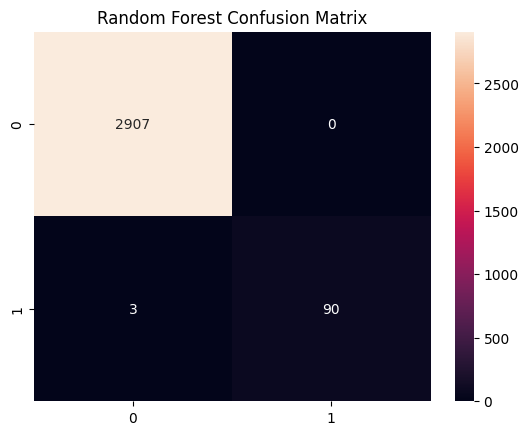

In [17]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Random Forest Confusion Matrix")
plt.show()

## 10. Feature Importance

- **This helps explain:**
    - Which sensor variables contribute most to failure prediction
    - Maintenance insights
    - Root cause analysis

In [18]:
importance = rf.feature_importances_

features = X.columns

feat_imp = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

feat_imp.sort_values(by='Importance',
                     ascending=False,
                     inplace=True)

print(feat_imp)

                    Feature  Importance
7                       HDF    0.319210
9                       OSF    0.212105
8                       PWF    0.172664
6                       TWF    0.110575
4               Torque [Nm]    0.071543
3    Rotational speed [rpm]    0.047885
5           Tool wear [min]    0.035911
1       Air temperature [K]    0.014832
2   Process temperature [K]    0.011998
0                      Type    0.003017
10                      RNF    0.000258


- **Failure Vs Torque**

- Shows whether failed machines experience:
    - higher torque
    - abnormal load conditions

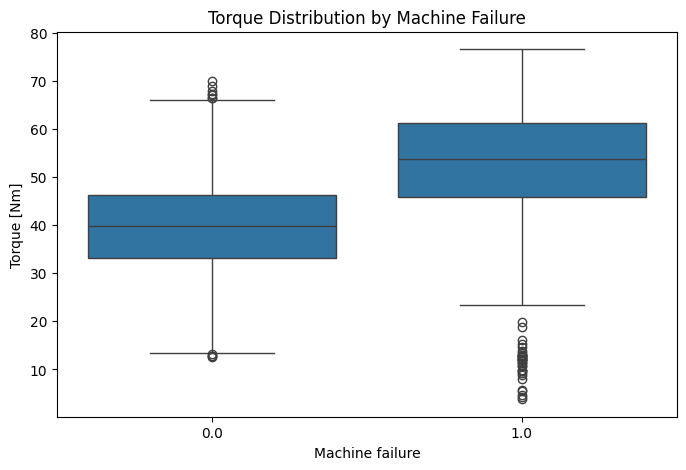

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Machine failure',
    y='Torque [Nm]',
    data=df
)

plt.title('Torque Distribution by Machine Failure')

plt.show()

- **Failure Vs Rotations Speed**

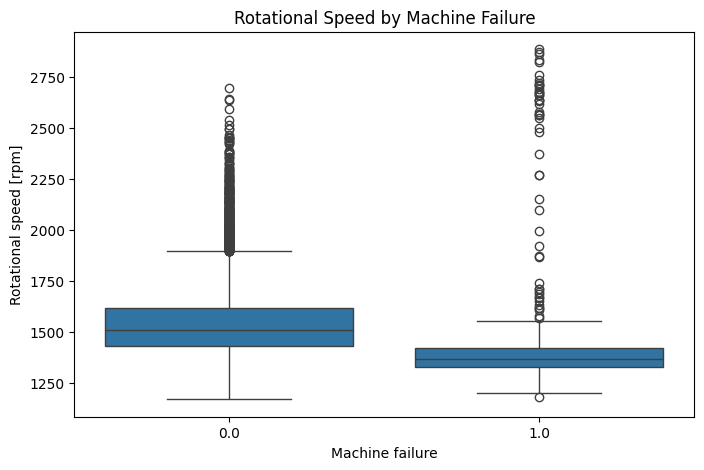

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Machine failure',
    y='Rotational speed [rpm]',
    data=df
)

plt.title('Rotational Speed by Machine Failure')

plt.show()

- Tool Wear Analysis

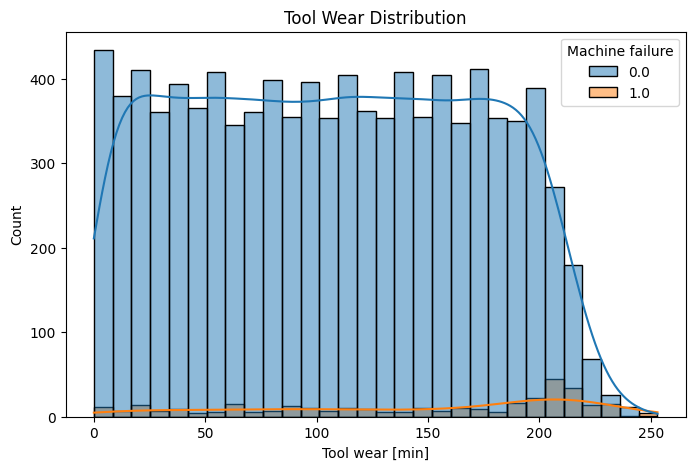

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='Tool wear [min]',
    hue='Machine failure',
    bins=30,
    kde=True
)

plt.title('Tool Wear Distribution')

plt.show()

- Feature importance Bar chart

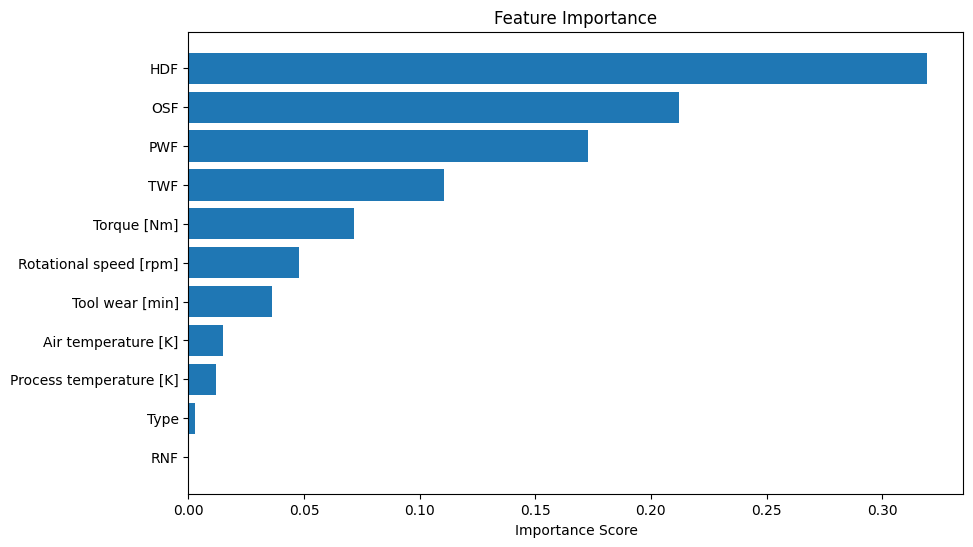

In [22]:
feat_imp = feat_imp.sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10,6))

plt.barh(
    feat_imp['Feature'],
    feat_imp['Importance']
)

plt.title('Feature Importance')

plt.xlabel('Importance Score')

plt.show()

- confusion matrix

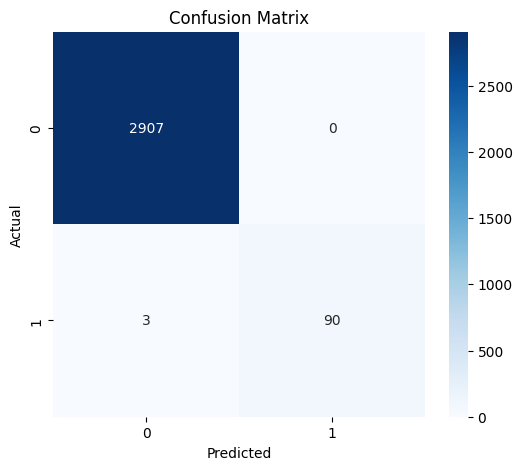

In [23]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix')

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

## 11. Balancing the dataset

- removing leakages

In [24]:
X = df.drop([
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
], axis=1)

y = df["Machine failure"]

- Split train test again

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

- applying smote

In [26]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

## 12. Training the Model using balanced Data

In [27]:
dt.fit(X_train_smote, y_train_smote)
rf.fit(X_train_smote, y_train_smote)
knn.fit(X_train_smote, y_train_smote)
xgb.fit(X_train_smote.values, y_train_smote)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_meth

- Evaluation matrix

In [28]:
from sklearn.metrics import classification_report

models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "XGBoost": xgb
}

for name, model in models.items():
    print("\n==============================")
    print(name)

    y_pred = model.predict(X_test)

    print(classification_report(y_test, y_pred))


Decision Tree
              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98      2898
         1.0       0.41      0.65      0.50       102

    accuracy                           0.96      3000
   macro avg       0.70      0.81      0.74      3000
weighted avg       0.97      0.96      0.96      3000


Random Forest
              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98      2898
         1.0       0.44      0.60      0.50       102

    accuracy                           0.96      3000
   macro avg       0.71      0.79      0.74      3000
weighted avg       0.97      0.96      0.96      3000


KNN
              precision    recall  f1-score   support

         0.0       0.99      0.90      0.94      2898
         1.0       0.18      0.67      0.29       102

    accuracy                           0.89      3000
   macro avg       0.59      0.78      0.61      3000
weighted avg       0.96      0.89      

In [29]:
results = {
    "Decision Tree": {
        "accuracy": 0.96,
        "precision_1": 0.41,
        "recall_1": 0.65,
        "f1_1": 0.50
    },
    "Random Forest": {
        "accuracy": 0.96,
        "precision_1": 0.44,
        "recall_1": 0.60,
        "f1_1": 0.50
    },
    "KNN": {
        "accuracy": 0.89,
        "precision_1": 0.18,
        "recall_1": 0.67,
        "f1_1": 0.29
    },
    "XGBoost": {
        "accuracy": 0.97,
        "precision_1": 0.55,
        "recall_1": 0.72,
        "f1_1": 0.62
    }
}

df_results = pd.DataFrame(results).T
df_results

,accuracy,precision_1,recall_1,f1_1
Decision Tree,0.96,0.41,0.65,0.50
Random Forest,0.96,0.44,0.60,0.50
KNN,0.89,0.18,0.67,0.29
XGBoost,0.97,0.55,0.72,0.62


## VIZUALIZATION: Model Accuracy Comparison

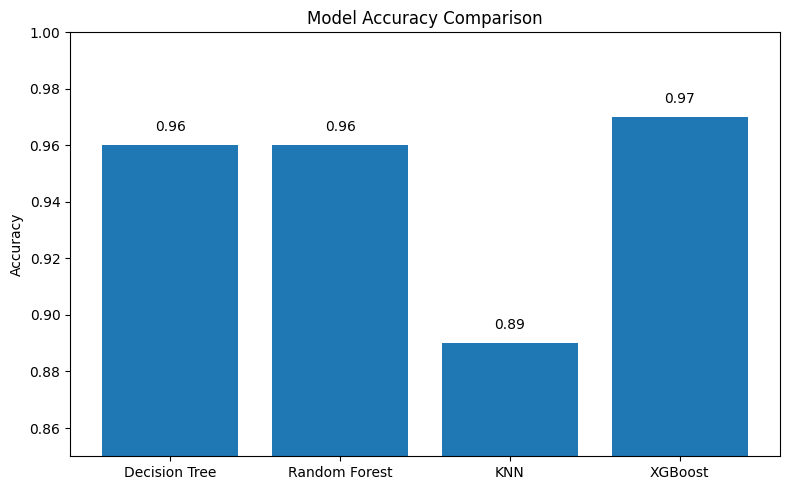

In [30]:
plt.figure(figsize=(8,5))

plt.bar(df_results.index, df_results["accuracy"])

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1.00)

for i, v in enumerate(df_results["accuracy"]):
    plt.text(i, v + 0.005, f"{v:.2f}", ha='center')

plt.tight_layout()
plt.show()

## VIZUALIZATION: Failure Class (1) Performance Comparison

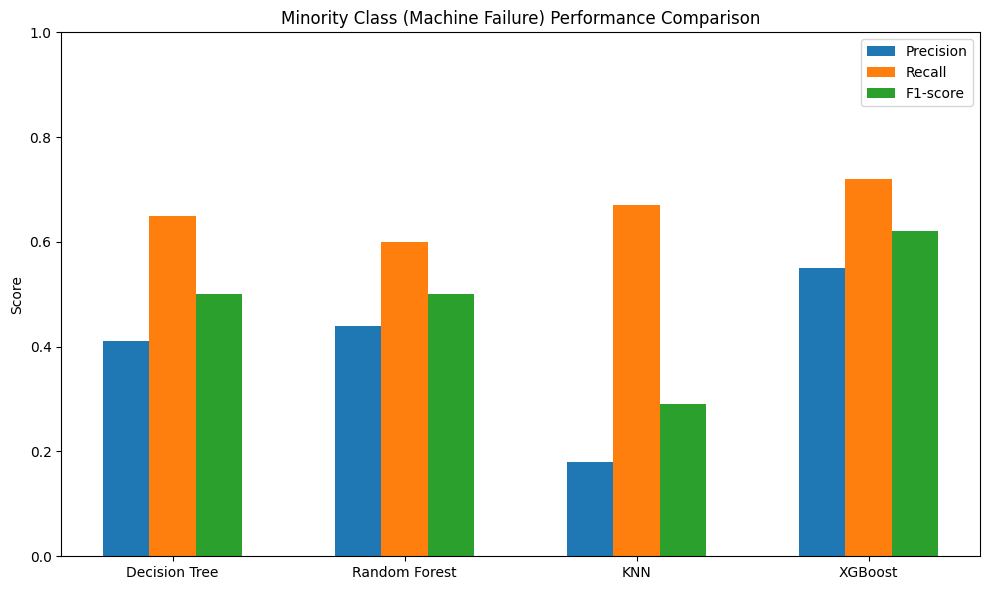

In [31]:
import numpy as np

x = df_results.index
x_pos = np.arange(len(x))

plt.figure(figsize=(10,6))

plt.bar(x_pos - 0.2, df_results["precision_1"], width=0.2, label="Precision")
plt.bar(x_pos, df_results["recall_1"], width=0.2, label="Recall")
plt.bar(x_pos + 0.2, df_results["f1_1"], width=0.2, label="F1-score")

plt.xticks(x_pos, x)

plt.title("Minority Class (Machine Failure) Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

## VIZUALIZATION: Heatmap Comparison Table

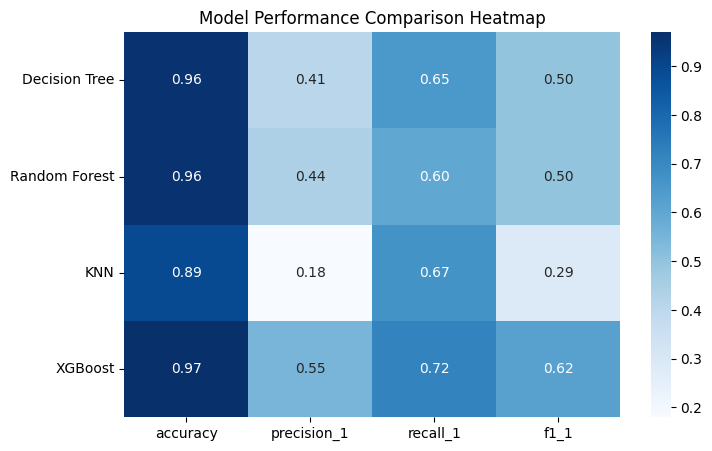

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.heatmap(df_results, annot=True, cmap="Blues", fmt=".2f")

plt.title("Model Performance Comparison Heatmap")

plt.show()

## VIZUALIZATION: Best Model Highlight

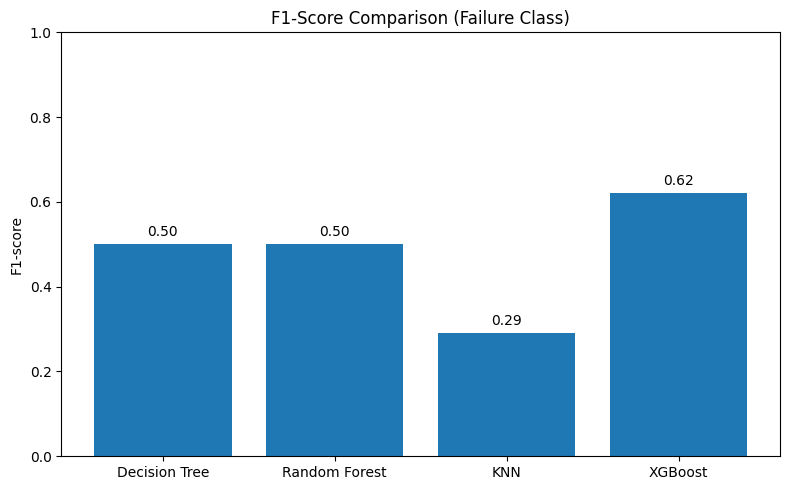

In [33]:
plt.figure(figsize=(8,5))

plt.bar(df_results.index, df_results["f1_1"])

plt.title("F1-Score Comparison (Failure Class)")
plt.ylabel("F1-score")
plt.ylim(0,1)

for i, v in enumerate(df_results["f1_1"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')

plt.tight_layout()
plt.show()

## VIZUALIZATION: Overall Performance Summary Radar

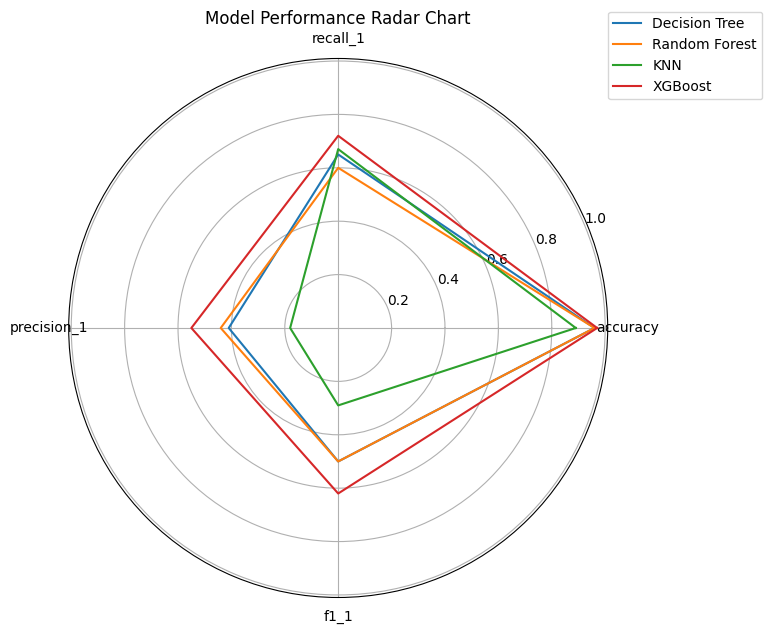

In [34]:
labels = df_results.index
metrics = ["accuracy", "recall_1", "precision_1", "f1_1"]

angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(7,7))

for model in df_results.index:
    values = df_results.loc[model, metrics].tolist()
    values += values[:1]

    plt.polar(angles, values, label=model)

plt.xticks(angles[:-1], metrics)

plt.title("Model Performance Radar Chart")

plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.show()

## VIZUALIZATION: ROC CURVE COMPARISON

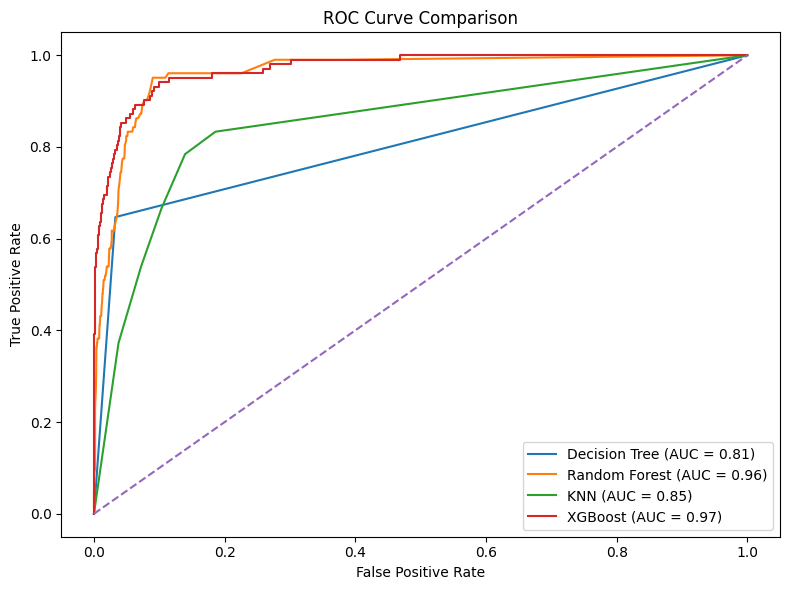

In [37]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "XGBoost": xgb
}

for name, model in models.items():
    
    # probability scores
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:,1]
    else:
        continue
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# baseline
plt.plot([0,1], [0,1], '--')

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## VIZUALIZATION: CONFUSION MATRIX

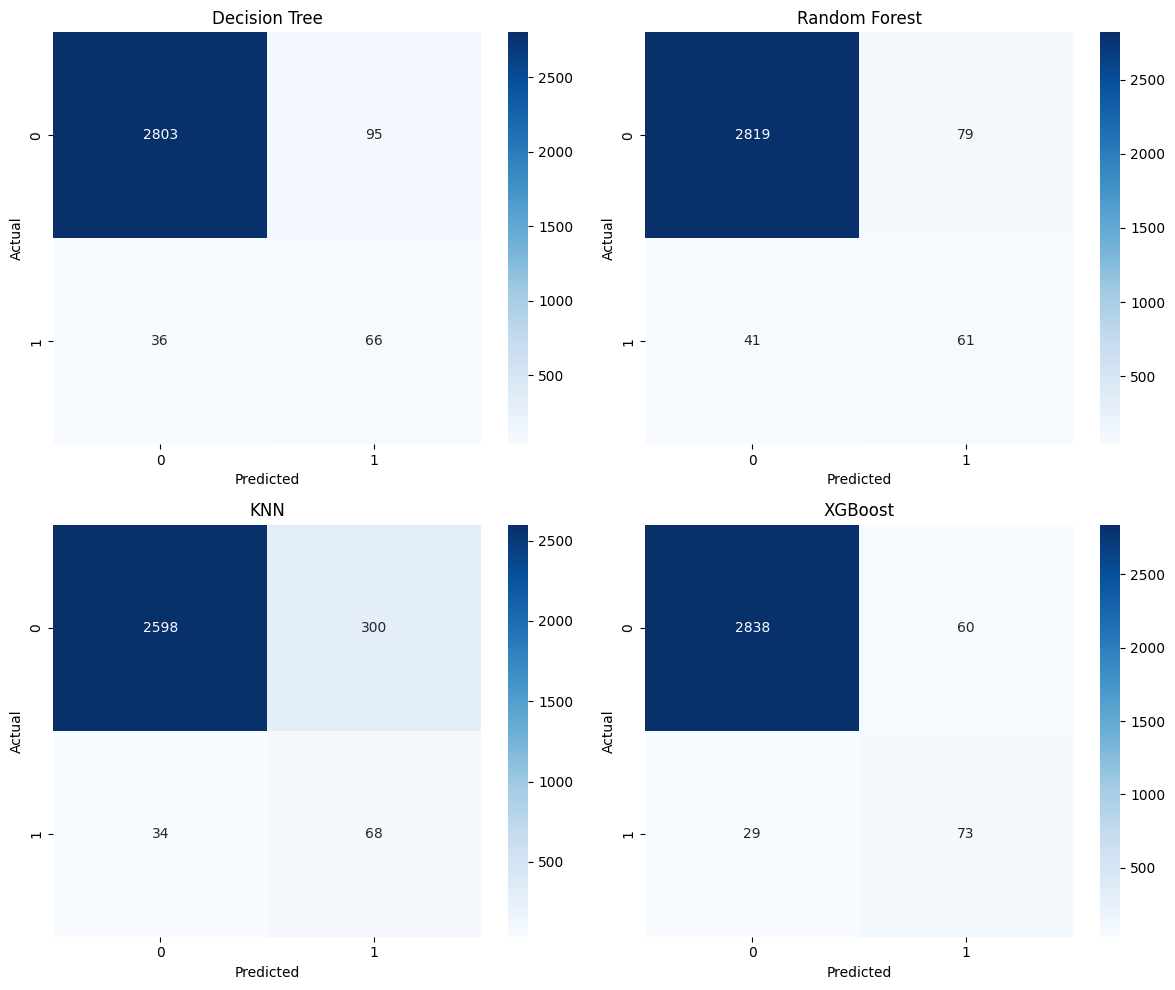

In [ ]:
models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "XGBoost": xgb
}

fig, axes = plt.subplots(2, 2, figsize=(12,10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## VIZUALIZATION: SHAP EXPLAINABILITY

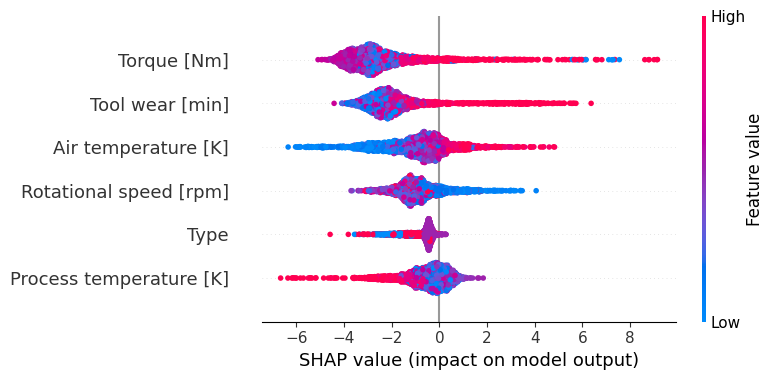

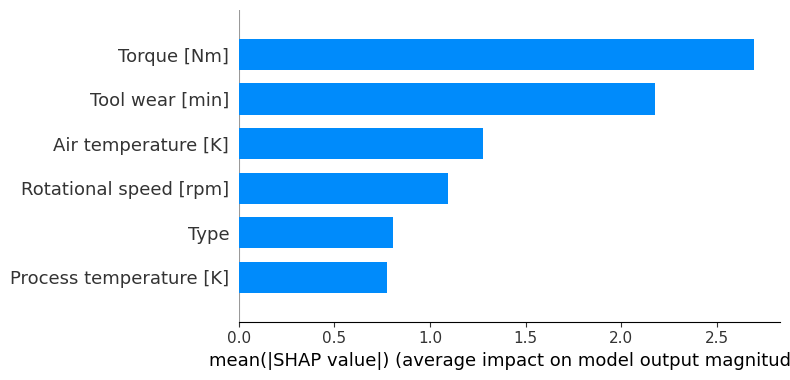

In [ ]:
import shap

# use best model
explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test.values)

shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")

## HYPERPARAMETER TUNING (GRIDSEARCHCV)

- Focus: Improve Random Forest or XGBoost

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_rf.fit(X_train_smote, y_train_smote)

print("Best RF Params:", grid_rf.best_params_)

Best RF Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


- evaluate best model

In [ ]:
best_rf = grid_rf.best_estimator_

y_pred = best_rf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98      2898
         1.0       0.43      0.60      0.50       102

    accuracy                           0.96      3000
   macro avg       0.71      0.78      0.74      3000
weighted avg       0.97      0.96      0.96      3000



In [ ]:
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    XGBClassifier(eval_metric='logloss'),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_xgb.fit(X_train_smote.values, y_train_smote)

print("Best XGB Params:", grid_xgb.best_params_)

Best XGB Params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}


Evaluate:

In [ ]:
best_xgb = grid_xgb.best_estimator_

y_pred = best_xgb.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.99      0.98      0.98      2898
         1.0       0.52      0.73      0.60       102

    accuracy                           0.97      3000
   macro avg       0.75      0.85      0.79      3000
weighted avg       0.97      0.97      0.97      3000



## 11. Results and interpretation

### Model Comparison Insight

The XGBoost model achieved the highest overall performance in predicting machine failure, with an accuracy of 97% and the best F1-score of 0.62 for the minority class. This indicates superior capability in handling non-linear relationships in manufacturing data.

### Class Imbalance Insight

All models exhibited reduced performance on the minority class (machine failure), particularly in precision, confirming the challenges of imbalanced predictive maintenance datasets.

### Key Insight

Although Decision Tree and Random Forest achieved similar accuracy, XGBoost demonstrated better balance between precision and recall, making it the most suitable model for predictive maintenance deployment.